# 01 — 데이터 구조 · 시간축 · 분포 이동 진단

LG Aimers 9기 / 투구 제구 성공 확률 예측

이 노트북이 답하려는 질문:

1. **시즌 분할 가설**: train = 2019~2024, test = 2025 인가?
2. **`asof_pitcher_n`의 구조**: 투수별 전역 단조 인덱스인가, 시즌마다 리셋되는가? gap은 없는가?
3. **`row_id`가 시간순인가?** (이후 모든 차분·이력 피처의 전제)
4. **분포 이동**: 시즌별 base rate에 계단이 있는가? (2024 ABS 도입 등)
5. **cold-start 규모**: 매 시즌 신규 투수/타자 비중은 얼마인가?

출력은 마지막 셀에서 한 번에 요약됩니다.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

DATA_DIR = "/content/drive/MyDrive/lgaimers_9/data"          # 환경에 맞게 수정
TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
TEST_PATH = os.path.join(DATA_DIR, "test.csv")

ID_COL = "row_id"
TARGET = "control_success"

findings = {}   # 마지막 요약 셀에서 사용

In [3]:
%%time
train = pd.read_csv(TRAIN_PATH, encoding="utf-8-sig")
print(train.shape)
print(f"memory: {train.memory_usage(deep=True).sum()/1e9:.2f} GB")
train.head(3)

(1475092, 49)
memory: 0.85 GB
CPU times: user 10.9 s, sys: 1.36 s, total: 12.2 s
Wall time: 16.3 s


,row_id,season,game_month,game_dayofweek,inning,top_bottom,game_type,balls_before,strikes_before,outs_before,run_top_before,run_bot_before,run_total_before,score_diff_home,score_diff_pitcher_team,runner_on_1b,runner_on_2b,runner_on_3b,num_runners_on,base_state,home_win_expectancy,away_win_expectancy,li,pitcher_id,batter_id,pitcher_hand,batter_hand,pitcher_team_id,batter_team_id,asof_pitcher_n,asof_pitcher_success_rate,asof_pitcher_reverse_rate,asof_pitcher_middle_rate,asof_pitcher_ball_rate,asof_pitcher_strike_rate,asof_pitcher_prev1_game_success_rate,asof_pitcher_prev3_game_success_rate,asof_pitcher_prev5_game_success_rate,asof_pitcher_prev1_game_middle_rate,asof_pitcher_prev3_game_middle_rate,asof_pitcher_prev5_game_middle_rate,asof_batter_n,asof_batter_success_rate,asof_batter_middle_rate,asof_pitcher_pitchmix_n,asof_pitcher_fastball_rate,asof_pitcher_breaking_rate,asof_pitcher_offspeed_rate,control_success
0,TRAIN_0000001,2019,3,5,1,T,R,0,0,0,0,0,0,0,0,0,0,0,0,___,50.0,50.0,0.87,21961,21996,1,2,16,13,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,0,NaN,NaN,NaN,0
1,TRAIN_0000002,2019,3,5,1,T,R,0,0,0,0,0,0,0,0,1,0,0,1,1__,46.5,53.5,1.44,21961,22103,1,1,16,13,1,0.0,1.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,1,1.0,0.0,0.0,0
2,TRAIN_0000003,2019,3,5,1,T,R,1,0,0,0,0,0,0,0,1,0,0,1,1__,46.5,53.5,1.44,21961,22103,1,1,16,13,2,0.0,0.5,0.0,0.5,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1,0.0,0.0,2,1.0,0.0,0.0,0


In [4]:
# 컬럼별 dtype / 결측 / 카디널리티 한 판
info = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_missing": train.isna().sum(),
    "pct_missing": (train.isna().mean() * 100).round(2),
    "nunique": train.nunique(dropna=True),
})
info

,dtype,n_missing,pct_missing,nunique
row_id,object,0,0.00,1475092
season,int64,0,0.00,6
game_month,int64,0,0.00,8
game_dayofweek,int64,0,0.00,7
inning,int64,0,0.00,13
top_bottom,object,0,0.00,2
game_type,object,0,0.00,2
balls_before,int64,0,0.00,4
strikes_before,int64,0,0.00,3
outs_before,int64,0,0.00,3


## 1. 시즌 분할 가설

train 1,475,092 / test 245,789 이 6:1 에 가까운지 확인한다.
시즌별 행 수가 대략 균등하고 2019~2024 만 있으면 **test = 2025 시즌 전체** 가설이 선다.

In [5]:
season_counts = train.groupby("season").size().rename("n_rows")
season_share = (season_counts / season_counts.sum() * 100).round(2).rename("pct")
print(pd.concat([season_counts, season_share], axis=1))

n_test = 245789
print()
print(f"train rows              : {len(train):,}")
print(f"test rows (공지)        : {n_test:,}")
print(f"train / 시즌수          : {len(train)/train['season'].nunique():,.0f}")
print(f"(train+test) / (시즌+1) : {(len(train)+n_test)/(train['season'].nunique()+1):,.0f}")

findings["seasons"] = sorted(train["season"].unique().tolist())
findings["season_counts"] = season_counts.to_dict()

        n_rows    pct
season               
2019    237413  16.09
2020    244087  16.55
2021    247088  16.75
2022    247472  16.78
2023    245525  16.64
2024    253507  17.19

train rows              : 1,475,092
test rows (공지)        : 245,789
train / 시즌수          : 245,849
(train+test) / (시즌+1) : 245,840


In [6]:
# test.csv 샘플(5건)의 season 값 확인 — 2025면 가설 확정
try:
    test_sample = pd.read_csv(TEST_PATH, encoding="utf-8-sig")
    print(test_sample[["row_id", "season", "game_month", "pitcher_id", "asof_pitcher_n"]])
    findings["test_seasons"] = sorted(test_sample["season"].unique().tolist())
except FileNotFoundError:
    print("test.csv 없음")

        row_id  season  game_month  pitcher_id  asof_pitcher_n
0  TEST_000001    2025           7       21813            3465
1  TEST_000017    2025           3       24745              86
2  TEST_000213    2025           6       24198             486
3  TEST_005332    2025           3       24713               0
4  TEST_035185    2025           3       24713               9


## 2. 타깃 base rate 와 평가식 스케일

$\text{Score} = 10^5 \times (1 - \mathrm{BS} / (r(1-r)))$ 이므로,
$r$ 을 알면 수료 기준 549.51 이 요구하는 절대 Brier Score 를 역산할 수 있다.

In [7]:
r_all = train[TARGET].mean()
print(f"전체 base rate r = {r_all:.6f}")

for s, sub in train.groupby("season"):
    r_s = sub[TARGET].mean()
    print(f"  {s}: r = {r_s:.6f}   (n={len(sub):,})")

denom = r_all * (1 - r_all)
print()
print(f"climatology Brier r(1-r) = {denom:.6f}")
for score in [549.51, 1000, 2000, 5000]:
    bs = denom * (1 - score / 1e5)
    print(f"  Score {score:>7.1f}  ->  BS <= {bs:.6f}   (BSS = {score/1e5:.5f})")

findings["r_all"] = float(r_all)
findings["r_by_season"] = train.groupby("season")[TARGET].mean().round(6).to_dict()

전체 base rate r = 0.523766
  2019: r = 0.564670   (n=237,413)
  2020: r = 0.532712   (n=244,087)
  2021: r = 0.532762   (n=247,088)
  2022: r = 0.528920   (n=247,472)
  2023: r = 0.499957   (n=245,525)
  2024: r = 0.486105   (n=253,507)

climatology Brier r(1-r) = 0.249435
  Score   549.5  ->  BS <= 0.248065   (BSS = 0.00550)
  Score  1000.0  ->  BS <= 0.246941   (BSS = 0.01000)
  Score  2000.0  ->  BS <= 0.244446   (BSS = 0.02000)
  Score  5000.0  ->  BS <= 0.236963   (BSS = 0.05000)


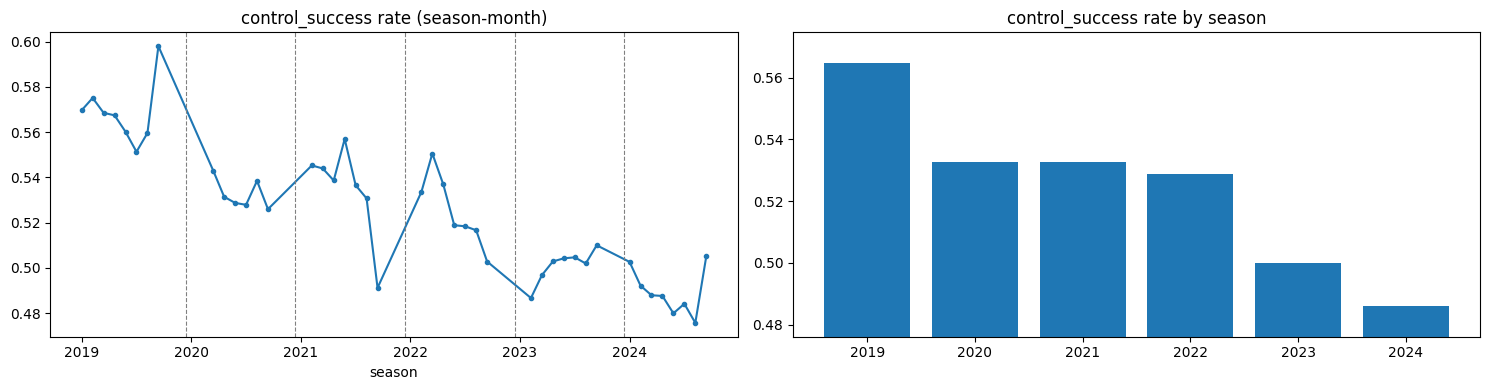

In [8]:
# 월 단위 추세 — 시즌 경계에 계단이 있는지 눈으로 확인
by_sm = (train.groupby(["season", "game_month"])[TARGET]
              .agg(["mean", "size"]).reset_index())
by_sm["t"] = by_sm["season"] + (by_sm["game_month"] - 3) / 10

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].plot(by_sm["t"], by_sm["mean"], marker="o", ms=3)
for s in sorted(train["season"].unique())[1:]:
    ax[0].axvline(s - 0.05, color="gray", ls="--", lw=0.8)
ax[0].set_title("control_success rate (season-month)")
ax[0].set_xlabel("season")

sc = train.groupby("season")[TARGET].mean()
ax[1].bar(sc.index.astype(str), sc.values)
ax[1].set_ylim(sc.min() - 0.01, sc.max() + 0.01)
ax[1].set_title("control_success rate by season")
plt.tight_layout(); plt.show()

## 3. `asof_pitcher_n` 구조 검증

세 가지를 본다.

- **전역성**: 투수별 `min == 0`, `max == count-1`, `nunique == count` 이면
  gap 없는 전역 0-based 인덱스다.
- **시즌 리셋**: (pitcher, season) 별 min 이 전부 0이면 시즌마다 리셋된다.
- **row_id 시간순**: 투수 내부에서 row_id 순서와 asof_n 순서가 일치하면
  row_id 가 그대로 연대순이라는 뜻이다.

In [9]:
g = train.groupby("pitcher_id")["asof_pitcher_n"]
chk = pd.DataFrame({
    "n_rows": g.size(),
    "n_min": g.min(),
    "n_max": g.max(),
    "n_unique": g.nunique(),
})
chk["contiguous"] = (chk["n_min"] == 0) & (chk["n_max"] == chk["n_rows"] - 1) & (chk["n_unique"] == chk["n_rows"])

print(f"투수 수: {len(chk):,}")
print(f"gap 없는 0-based 전역 인덱스인 투수 비율: {chk['contiguous'].mean():.4f}")
print()
print("위반 사례 (상위 10):")
print(chk.loc[~chk["contiguous"]].head(10))

findings["asof_n_contiguous_frac"] = float(chk["contiguous"].mean())

투수 수: 792
gap 없는 0-based 전역 인덱스인 투수 비율: 1.0000

위반 사례 (상위 10):
Empty DataFrame
Columns: [n_rows, n_min, n_max, n_unique, contiguous]
Index: []


In [10]:
# 시즌 리셋 여부
per_ps = train.groupby(["pitcher_id", "season"])["asof_pitcher_n"].min().reset_index()
first_season = train.groupby("pitcher_id")["season"].min().rename("first_season")
per_ps = per_ps.merge(first_season, on="pitcher_id")
later = per_ps[per_ps["season"] > per_ps["first_season"]]

print("첫 시즌이 아닌 (pitcher, season) 조합의 asof_pitcher_n 최솟값 분포:")
print(later["asof_pitcher_n"].describe())
print()
print(f"그중 min == 0 인 비율: {(later['asof_pitcher_n'] == 0).mean():.4f}")
print("  -> 1.0 에 가까우면 시즌 리셋, 0.0 에 가까우면 전역 누적")

findings["asof_n_resets_by_season"] = float((later["asof_pitcher_n"] == 0).mean())

첫 시즌이 아닌 (pitcher, season) 조합의 asof_pitcher_n 최솟값 분포:
count     1468.000000
mean      1733.680518
std       2021.969076
min          4.000000
25%        275.500000
50%        995.500000
75%       2438.250000
max      13637.000000
Name: asof_pitcher_n, dtype: float64

그중 min == 0 인 비율: 0.0000
  -> 1.0 에 가까우면 시즌 리셋, 0.0 에 가까우면 전역 누적


In [11]:
# row_id 가 연대순인가: 투수 내부에서 row_id 순 == asof_n 순 인지
tmp = train[[ID_COL, "pitcher_id", "asof_pitcher_n"]].copy()
tmp["row_num"] = tmp[ID_COL].str.slice(6).astype(np.int64)
tmp = tmp.sort_values(["pitcher_id", "row_num"])
diff = tmp.groupby("pitcher_id")["asof_pitcher_n"].diff()
viol = (diff.dropna() != 1).mean()
print(f"row_id 순으로 asof_pitcher_n 이 정확히 +1 씩 증가하지 않는 비율: {viol:.6f}")
print("  -> 0 이면 row_id 가 그대로 연대순 (모든 차분/이력 작업의 전제)")

findings["row_id_is_chronological"] = float(1 - viol)

row_id 순으로 asof_pitcher_n 이 정확히 +1 씩 증가하지 않는 비율: 0.000000
  -> 0 이면 row_id 가 그대로 연대순 (모든 차분/이력 작업의 전제)


In [12]:
# 배터 쪽도 동일하게
gb = train.groupby("batter_id")["asof_batter_n"]
chk_b = pd.DataFrame({"n_rows": gb.size(), "n_min": gb.min(), "n_max": gb.max(), "n_unique": gb.nunique()})
chk_b["contiguous"] = (chk_b["n_min"] == 0) & (chk_b["n_max"] == chk_b["n_rows"] - 1) & (chk_b["n_unique"] == chk_b["n_rows"])
print(f"타자 수: {len(chk_b):,}   gap 없는 비율: {chk_b['contiguous'].mean():.4f}")

타자 수: 830   gap 없는 비율: 1.0000


## 4. cold-start 규모

test(2025) 에서 `asof_pitcher_n == 0` 인 신규 투수 비중을 직접은 못 보지만,
**과거 시즌에서 신규 진입 비율** 을 재면 좋은 대리 추정이 된다.
검증 시즌에서 이 비율이 재현되는지도 확인해야 한다.

In [13]:
seasons = sorted(train["season"].unique())
rows = []
for i, s in enumerate(seasons):
    cur = train[train["season"] == s]
    if i == 0:
        rows.append({"season": s, "pct_rows_new_pitcher": np.nan, "pct_rows_new_batter": np.nan,
                     "pct_rows_asof_n0": (cur["asof_pitcher_n"] == 0).mean() * 100})
        continue
    prev_p = set(train.loc[train["season"] < s, "pitcher_id"].unique())
    prev_b = set(train.loc[train["season"] < s, "batter_id"].unique())
    rows.append({
        "season": s,
        "pct_rows_new_pitcher": (~cur["pitcher_id"].isin(prev_p)).mean() * 100,
        "pct_rows_new_batter": (~cur["batter_id"].isin(prev_b)).mean() * 100,
        "pct_rows_asof_n0": (cur["asof_pitcher_n"] == 0).mean() * 100,
    })
newcomer = pd.DataFrame(rows).round(3)
print(newcomer)
findings["newcomer_table"] = newcomer.to_dict("records")

   season  pct_rows_new_pitcher  pct_rows_new_batter  pct_rows_asof_n0
0    2019                   NaN                  NaN             0.150
1    2020                22.378               11.602             0.045
2    2021                20.567                8.775             0.038
3    2022                15.739               11.023             0.036
4    2023                13.798                9.405             0.026
5    2024                19.861                9.305             0.032


In [14]:
# asof_pitcher_n 구간별 base rate — 표본이 쌓일수록 예측 가능성이 오르는지
bins = [-1, 0, 10, 50, 200, 1000, 5000, np.inf]
labels = ["0", "1-10", "11-50", "51-200", "201-1000", "1001-5000", "5000+"]
train["_nbin"] = pd.cut(train["asof_pitcher_n"], bins=bins, labels=labels)
tbl = train.groupby("_nbin", observed=True).agg(
    n_rows=(TARGET, "size"),
    base_rate=(TARGET, "mean"),
    pct=(TARGET, lambda x: len(x) / len(train) * 100),
).round(4)
print(tbl)
train.drop(columns=["_nbin"], inplace=True)

           n_rows  base_rate      pct
_nbin                                
0             792     0.5518   0.0537
1-10         7896     0.5447   0.5353
11-50       29752     0.5486   2.0170
51-200      94711     0.5378   6.4207
201-1000   362264     0.5304  24.5587
1001-5000  739976     0.5208  50.1647
5000+      239701     0.5133  16.2499


In [15]:
# asof_* 결측 패턴
asof_cols = [c for c in train.columns if c.startswith("asof_")]
miss = train[asof_cols].isna().mean().mul(100).round(3).sort_values(ascending=False)
print(miss)

asof_pitcher_prev5_game_success_rate    1.979
asof_pitcher_prev1_game_middle_rate     1.979
asof_pitcher_prev1_game_success_rate    1.979
asof_pitcher_prev3_game_middle_rate     1.979
asof_pitcher_prev5_game_middle_rate     1.979
asof_pitcher_prev3_game_success_rate    1.979
asof_batter_success_rate                0.056
asof_batter_middle_rate                 0.056
asof_pitcher_ball_rate                  0.054
asof_pitcher_success_rate               0.054
asof_pitcher_reverse_rate               0.054
asof_pitcher_offspeed_rate              0.054
asof_pitcher_middle_rate                0.054
asof_pitcher_strike_rate                0.054
asof_pitcher_fastball_rate              0.054
asof_pitcher_breaking_rate              0.054
asof_pitcher_n                          0.000
asof_batter_n                           0.000
asof_pitcher_pitchmix_n                 0.000
dtype: float64


## 5. 범주형 / ID 카디널리티

`game_type`, `top_bottom`, `base_state` 는 인코딩 대상.
`pitcher_id` / `batter_id` 는 카디널리티가 크면 target encoding 대신
`asof_*` 를 신뢰하는 편이 낫다.

In [16]:
for c in ["top_bottom", "game_type", "base_state", "pitcher_hand", "batter_hand",
          "pitcher_team_id", "batter_team_id"]:
    vc = train[c].value_counts(dropna=False)
    print(f"--- {c}  (nunique={train[c].nunique(dropna=False)}) ---")
    print(vc.head(12))
    print()

print(f"pitcher_id nunique: {train['pitcher_id'].nunique():,}")
print(f"batter_id  nunique: {train['batter_id'].nunique():,}")

--- top_bottom  (nunique=2) ---
top_bottom
T    752812
B    722280
Name: count, dtype: int64

--- game_type  (nunique=2) ---
game_type
R    1314088
F     161004
Name: count, dtype: int64

--- base_state  (nunique=8) ---
base_state
___    777248
1__    293724
12_    125831
_2_    113627
1_3     48839
123     48408
__3     35513
_23     31902
Name: count, dtype: int64

--- pitcher_hand  (nunique=2) ---
pitcher_hand
2    1093741
1     381351
Name: count, dtype: int64

--- batter_hand  (nunique=2) ---
batter_hand
2    779345
1    695747
Name: count, dtype: int64

--- pitcher_team_id  (nunique=13) ---
pitcher_team_id
13    208662
17    148166
21    146794
12    145926
14    141953
15    137418
19    137001
18    137000
16    136193
20    130574
23      4437
22       676
Name: count, dtype: int64

--- batter_team_id  (nunique=13) ---
batter_team_id
13    213325
14    145937
17    144335
21    143335
12    142405
20    139297
19    135761
16    135581
18    134642
15    134524
23      4885
22

In [17]:
# 팀 x 시즌 교차표 — 팀 ID 가 시즌에 걸쳐 안정적인지 (Trackman 매핑 시도 시 필요)
print(pd.crosstab(train["pitcher_team_id"], train["season"]))

season            2019   2020   2021   2022   2023   2024
pitcher_team_id                                          
12               21924  24883  24108  25163  24435  25413
13               33717  32907  34240  35983  34583  37232
14               22190  24289  23539  24085  23769  24081
15               22713  21812  23714  22765  23112  23302
16               22279  22134  23079  22697  22547  23457
17               23931  25422  24691  25005  24198  24919
18               22555  22646  23056  23092  22842  22809
19               22356  22868  23130  22838  22705  23104
20               21496  21967  21933  21199  21239  22740
21               22768  25159  24794  23979  24914  25180
22                 676      0      0      0      0      0
23                 808      0    804    666   1181    978
25                   0      0      0      0      0    292


## 6. 요약

In [18]:
print("=" * 70)
print("요약")
print("=" * 70)
print(f"시즌               : {findings['seasons']}")
print(f"test.csv 샘플 시즌 : {findings.get('test_seasons')}")
print(f"전체 base rate r   : {findings['r_all']:.6f}   ->  r(1-r) = {findings['r_all']*(1-findings['r_all']):.6f}")
print(f"asof_n 전역 연속   : {findings['asof_n_contiguous_frac']:.4f}  (1.0 이면 gap 없는 전역 인덱스)")
print(f"asof_n 시즌 리셋   : {findings['asof_n_resets_by_season']:.4f}  (1.0 이면 리셋, 0.0 이면 누적)")
print(f"row_id 연대순      : {findings['row_id_is_chronological']:.6f}  (1.0 이어야 함)")
print()
print("시즌별 base rate:")
for s, v in findings["r_by_season"].items():
    print(f"  {s}: {v:.6f}")
print()
print("신규 진입 비율(%):")
for rec in findings["newcomer_table"]:
    print(f"  {rec['season']}: new_pitcher={rec['pct_rows_new_pitcher']}, "
          f"new_batter={rec['pct_rows_new_batter']}, asof_n0={rec['pct_rows_asof_n0']}")

요약
시즌               : [2019, 2020, 2021, 2022, 2023, 2024]
test.csv 샘플 시즌 : [2025]
전체 base rate r   : 0.523766   ->  r(1-r) = 0.249435
asof_n 전역 연속   : 1.0000  (1.0 이면 gap 없는 전역 인덱스)
asof_n 시즌 리셋   : 0.0000  (1.0 이면 리셋, 0.0 이면 누적)
row_id 연대순      : 1.000000  (1.0 이어야 함)

시즌별 base rate:
  2019: 0.564670
  2020: 0.532712
  2021: 0.532762
  2022: 0.528920
  2023: 0.499957
  2024: 0.486105

신규 진입 비율(%):
  2019: new_pitcher=nan, new_batter=nan, asof_n0=0.15
  2020: new_pitcher=22.378, new_batter=11.602, asof_n0=0.045
  2021: new_pitcher=20.567, new_batter=8.775, asof_n0=0.038
  2022: new_pitcher=15.739, new_batter=11.023, asof_n0=0.036
  2023: new_pitcher=13.798, new_batter=9.405, asof_n0=0.026
  2024: new_pitcher=19.861, new_batter=9.305, asof_n0=0.032


In [19]:
# ── game_type R/F 분리 진단 ──────────────────────────────────────────
import numpy as np
import pandas as pd

TARGET = "control_success"

# (1) 전체 규모와 base rate
gt = train.groupby("game_type").agg(
    n_rows=(TARGET, "size"),
    base_rate=(TARGET, "mean"),
).assign(pct=lambda d: (d["n_rows"] / len(train) * 100).round(2)).round(6)
print("=== game_type 전체 ===")
print(gt)

# (2) 시즌 x game_type base rate — 드리프트가 어느 쪽에서 오는지
piv_rate = train.pivot_table(index="season", columns="game_type",
                             values=TARGET, aggfunc="mean").round(6)
piv_n = train.pivot_table(index="season", columns="game_type",
                          values=TARGET, aggfunc="size")
piv_share = (piv_n.div(piv_n.sum(axis=1), axis=0) * 100).round(2)

print("\n=== 시즌별 base rate (game_type별) ===")
print(piv_rate)
print("\n=== 시즌별 행 수 ===")
print(piv_n)
print("\n=== 시즌별 F 구성비(%) ===")
print(piv_share)

# (3) 시즌간 변화량 분해:
#     전체 하락 중 (a) 각 그룹 내부 하락분 (b) 구성비 이동분
#     Δr = Σ_g w_g Δr_g  +  Σ_g r_g Δw_g   (shift-share decomposition)
w = piv_n.div(piv_n.sum(axis=1), axis=0)          # 구성비
r = piv_rate
rows = []
for i in range(1, len(r)):
    s_prev, s_cur = r.index[i - 1], r.index[i]
    dw = w.loc[s_cur] - w.loc[s_prev]
    dr = r.loc[s_cur] - r.loc[s_prev]
    within = (w.loc[s_prev] * dr).sum()            # 그룹 내부 변화
    between = (r.loc[s_prev] * dw).sum()           # 구성비 변화
    inter = (dw * dr).sum()                        # 교차항
    total = (w.loc[s_cur] * r.loc[s_cur]).sum() - (w.loc[s_prev] * r.loc[s_prev]).sum()
    rows.append({"transition": f"{s_prev}->{s_cur}", "total": total,
                 "within": within, "between": between, "interaction": inter})
print("\n=== base rate 변화 분해 (within = 그룹 내부, between = R/F 구성비 이동) ===")
print(pd.DataFrame(rows).round(6).to_string(index=False))

# (4) F가 다른 환경인지: 상황 분포 비교
print("\n=== R vs F 분포 비교 ===")
for c in ["inning", "balls_before", "strikes_before", "outs_before",
          "pitcher_hand", "num_runners_on", "game_month"]:
    comp = train.pivot_table(index=c, columns="game_type", values=TARGET, aggfunc="size")
    comp = (comp / comp.sum() * 100).round(2)
    print(f"\n--- {c} (열별 % 분포) ---")
    print(comp)

# (5) F 소속 투수가 R에도 나오는가 — 같은 선수 풀인지
p_R = set(train.loc[train["game_type"] == "R", "pitcher_id"])
p_F = set(train.loc[train["game_type"] == "F", "pitcher_id"])
print(f"\nR 투수 {len(p_R)} / F 투수 {len(p_F)} / 교집합 {len(p_R & p_F)}")
print(f"F 전용 투수: {len(p_F - p_R)},  R 전용 투수: {len(p_R - p_F)}")

# (6) 같은 투수의 R vs F 제구 성공률 차이 (짝지은 비교)
both = train[train["pitcher_id"].isin(p_R & p_F)]
paired = both.pivot_table(index="pitcher_id", columns="game_type",
                          values=TARGET, aggfunc=["mean", "size"])
paired.columns = ["rate_F", "rate_R", "n_F", "n_R"]
paired = paired[(paired["n_F"] >= 100) & (paired["n_R"] >= 100)]
paired["diff_F_minus_R"] = paired["rate_F"] - paired["rate_R"]
print(f"\n=== 같은 투수 R vs F 짝지은 차이 (n>=100 양쪽, {len(paired)}명) ===")
print(paired["diff_F_minus_R"].describe().round(6))
print(f"평균 차이: {paired['diff_F_minus_R'].mean():+.6f}  "
      f"(0에서 멀면 F는 다른 환경)")

# (7) asof_* 가 R/F를 섞어서 계산됐는지 — 섞였다면 피처 자체가 오염
#     투수별로 F 비중이 높을수록 asof_success_rate가 체계적으로 치우치는지
tmp = train.groupby("pitcher_id").agg(
    f_share=("game_type", lambda s: (s == "F").mean()),
    final_asof=("asof_pitcher_success_rate", "last"),
    overall=(TARGET, "mean"),
    n=(TARGET, "size"),
).query("n >= 500")
print(f"\nF비중 vs 최종 asof_success_rate 상관: "
      f"{tmp['f_share'].corr(tmp['final_asof']):.4f}  (n={len(tmp)})")

=== game_type 전체 ===
            n_rows  base_rate    pct
game_type                           
F           161004   0.603271  10.91
R          1314088   0.514025  89.09

=== 시즌별 base rate (game_type별) ===
game_type         F         R
season                       
2019       0.689250  0.549490
2020       0.587774  0.526925
2021       0.703840  0.512763
2022       0.708749  0.503691
2023       0.472904  0.503118
2024       0.459280  0.489707

=== 시즌별 행 수 ===
game_type      F       R
season                  
2019       25786  211627
2020       23213  220874
2021       25861  221227
2022       30448  217024
2023       25686  219839
2024       30010  223497

=== 시즌별 F 구성비(%) ===
game_type      F      R
season                 
2019       10.86  89.14
2020        9.51  90.49
2021       10.47  89.53
2022       12.30  87.70
2023       10.46  89.54
2024       11.84  88.16

=== base rate 변화 분해 (within = 그룹 내부, between = R/F 구성비 이동) ===
transition     total    within   between  interaction
2019->

In [20]:
# ── 소수 팀 ID 정체 파악 ─────────────────────────────────────────────
MAIN_TEAMS = set(range(12, 22))          # 12~21 = 주력 10팀
odd = sorted(set(train["pitcher_team_id"]) | set(train["batter_team_id"]) - MAIN_TEAMS)
odd = [t for t in odd if t not in MAIN_TEAMS]
print("예외 팀 ID:", odd)

rows = []
for t in odd:
    m = (train["pitcher_team_id"] == t) | (train["batter_team_id"] == t)
    sub = train[m]
    rows.append({
        "team_id": t,
        "n_rows": len(sub),
        "seasons": sorted(sub["season"].unique()),
        "months": sorted(sub["game_month"].unique()),
        "game_type": sub["game_type"].value_counts().to_dict(),
        "base_rate": round(sub[TARGET].mean(), 4),
        "n_pitchers": sub["pitcher_id"].nunique(),
        "n_batters": sub["batter_id"].nunique(),
    })
print(pd.DataFrame(rows).to_string(index=False))

# 상대 팀 분포 — 주력 10팀과 붙는지, 자기들끼리만 붙는지
for t in odd:
    sub = train[train["pitcher_team_id"] == t]
    if len(sub) == 0:
        continue
    print(f"\n--- team {t} 이 투구할 때 상대 타자팀 분포 ---")
    print(sub["batter_team_id"].value_counts().head(12))

# 해당 팀 소속 투수가 주력 팀에서도 던지는가 (이적 vs 별개 풀)
for t in odd:
    ps = set(train.loc[train["pitcher_team_id"] == t, "pitcher_id"])
    if not ps:
        continue
    also_main = train[train["pitcher_id"].isin(ps) &
                      train["pitcher_team_id"].isin(MAIN_TEAMS)]
    print(f"\nteam {t}: 투수 {len(ps)}명, "
          f"그중 주력팀에서도 등판한 투수 {also_main['pitcher_id'].nunique()}명, "
          f"주력팀 등판 행 수 {len(also_main):,}")

# 제외했을 때 시즌별 base rate가 얼마나 바뀌는지 (외삽 판단에 영향)
mask_main = train["pitcher_team_id"].isin(MAIN_TEAMS) & train["batter_team_id"].isin(MAIN_TEAMS)
cmp = pd.DataFrame({
    "all": train.groupby("season")[TARGET].mean(),
    "main_only": train[mask_main].groupby("season")[TARGET].mean(),
})
cmp["diff"] = cmp["main_only"] - cmp["all"]
print("\n=== 예외 팀 제외 전후 시즌별 base rate ===")
print(cmp.round(6))
print(f"\n예외 팀 관련 행: {(~mask_main).sum():,} ({(~mask_main).mean()*100:.3f}%)")

예외 팀 ID: [22, 23, 25]
 team_id  n_rows                        seasons          months   game_type  base_rate  n_pitchers  n_batters
      22    1449                         [2019]       [3, 4, 5] {'F': 1449}     0.6881          25         32
      23    9322 [2019, 2021, 2022, 2023, 2024] [5, 6, 7, 8, 9] {'F': 9322}     0.6086         114        127
      25     584                         [2024]             [4]  {'F': 584}     0.4538          15         25

--- team 22 이 투구할 때 상대 타자팀 분포 ---
batter_team_id
13    676
Name: count, dtype: int64

--- team 23 이 투구할 때 상대 타자팀 분포 ---
batter_team_id
13    4437
Name: count, dtype: int64

--- team 25 이 투구할 때 상대 타자팀 분포 ---
batter_team_id
13    292
Name: count, dtype: int64

team 22: 투수 8명, 그중 주력팀에서도 등판한 투수 7명, 주력팀 등판 행 수 2,244

team 23: 투수 58명, 그중 주력팀에서도 등판한 투수 57명, 주력팀 등판 행 수 88,350

team 25: 투수 1명, 그중 주력팀에서도 등판한 투수 0명, 주력팀 등판 행 수 0

=== 예외 팀 제외 전후 시즌별 base rate ===
             all  main_only      diff
season                               
2019 

game_type            F       R  F_share_of_all_F
pitcher_team_id                                 
12               13191  132735              8.19
13               79583  129079             49.43
14               13747  128206              8.54
15                4411  133007              2.74
16                4346  131847              2.70
17               13302  134864              8.26
18                4303  132697              2.67
19                4600  132401              2.86
20                4508  126066              2.80
21               13608  133186              8.45
22                 676       0              0.42
23                4437       0              2.76
25                 292       0              0.18

F 행 중 팀13이 한쪽에 있는 비율: 1.0000

F 경기의 팀 조합 상위:
pitcher_team_id  batter_team_id
14               13                13747
21               13                13608
13               14                13432
17               13                13302
12               13    

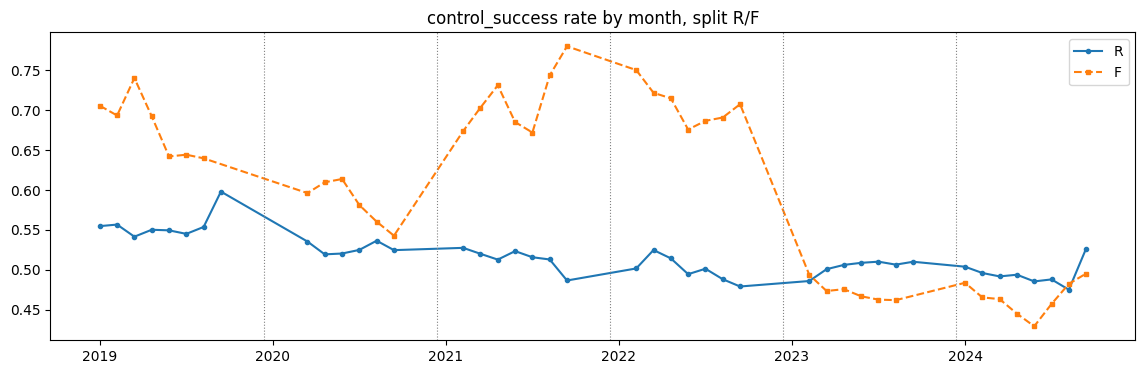


trackman pitcher_hand: {'Right': 74.91, 'Left': 25.09}
trackman batter_hand : {'Right': 53.96, 'Left': 46.04}
main   pitcher_hand: {2: 74.15, 1: 25.85}
main   batter_hand : {2: 52.83, 1: 47.17}
main R pitcher_hand: {2: 74.44, 1: 25.56}

test sample game_type: {'R': 5}


In [21]:
# ── (1) F가 팀 13 전용인가 ────────────────────────────────────────
ct = pd.crosstab(train["pitcher_team_id"], train["game_type"])
ct["F_share_of_all_F"] = (ct.get("F", 0) / ct.get("F", 0).sum() * 100).round(2)
print(ct)

f = train[train["game_type"] == "F"]
involves_13 = ((f["pitcher_team_id"] == 13) | (f["batter_team_id"] == 13)).mean()
print(f"\nF 행 중 팀13이 한쪽에 있는 비율: {involves_13:.4f}")
print("\nF 경기의 팀 조합 상위:")
print(f.groupby(["pitcher_team_id", "batter_team_id"]).size()
       .sort_values(ascending=False).head(15))

# R만 볼 때 팀별 행 수가 균등한지
print("\nR만: 팀별 투구 행 수")
print(train[train["game_type"] == "R"]["pitcher_team_id"].value_counts().sort_index())

# ── (2) 같은 투수 R vs F 차이를 시즌별로 ──────────────────────────
rows = []
for s, sub in train.groupby("season"):
    p = sub.pivot_table(index="pitcher_id", columns="game_type",
                        values=TARGET, aggfunc=["mean", "size"])
    p.columns = ["rate_F", "rate_R", "n_F", "n_R"]
    p = p.dropna()
    p = p[(p["n_F"] >= 50) & (p["n_R"] >= 50)]
    rows.append({"season": s, "n_pitchers": len(p),
                 "mean_diff_F_minus_R": p["rate_F"].sub(p["rate_R"]).mean()})
print(pd.DataFrame(rows).round(4).to_string(index=False))
#  -> 2022 이전 +0.2대, 2023 이후 0 근처면 라벨 생성 과정 변화 확정

# ── (3) 월별 추세를 R/F 분리 ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 4))
for gt, style in [("R", "-o"), ("F", "--s")]:
    d = (train[train["game_type"] == gt]
         .groupby(["season", "game_month"])[TARGET].mean().reset_index())
    ax.plot(d["season"] + (d["game_month"] - 3) / 10, d[TARGET], style, ms=3, label=gt)
for s in sorted(train["season"].unique())[1:]:
    ax.axvline(s - 0.05, color="gray", ls=":", lw=0.8)
ax.legend(); ax.set_title("control_success rate by month, split R/F"); plt.show()

# ── (4) hand 코딩 확정: trackman 마진과 대조 ──────────────────────
tm = pd.read_csv(os.path.join(DATA_DIR, "trackman_history.csv"),
                 usecols=["season", "pitcher_hand", "batter_hand"])
print("\ntrackman pitcher_hand:", (tm["pitcher_hand"].value_counts(normalize=True) * 100).round(2).to_dict())
print("trackman batter_hand :", (tm["batter_hand"].value_counts(normalize=True) * 100).round(2).to_dict())
print("main   pitcher_hand:", (train["pitcher_hand"].value_counts(normalize=True) * 100).round(2).to_dict())
print("main   batter_hand :", (train["batter_hand"].value_counts(normalize=True) * 100).round(2).to_dict())
# trackman은 R(1군) 로그일 가능성이 높으니 train의 R 부분과 비교하는 게 정확
r_only = train[train["game_type"] == "R"]
print("main R pitcher_hand:", (r_only["pitcher_hand"].value_counts(normalize=True) * 100).round(2).to_dict())

# ── (5) test에 F가 있는가 ────────────────────────────────────────
print("\ntest sample game_type:", test_sample["game_type"].value_counts().to_dict()
      if "game_type" in test_sample.columns else "컬럼 없음")

In [22]:
tmp = train.groupby("pitcher_id").agg(
    f_share=("game_type", lambda s: (s == "F").mean()),
    main_team=("pitcher_team_id", lambda s: s.mode().iloc[0]),
    final_asof=("asof_pitcher_success_rate", "last"),
    n=("control_success", "size"),
).query("n >= 500")
print(tmp.groupby("main_team")[["f_share", "final_asof"]].agg(["mean", "count"]).round(4))
print("\n팀13 제외 후 상관:", tmp.query("main_team != 13")["f_share"].corr(tmp.query("main_team != 13")["final_asof"]).round(4))

          f_share       final_asof      
             mean count       mean count
main_team                               
12         0.1292    46     0.5253    46
13         0.5272    68     0.5503    68
14         0.1313    44     0.5179    44
15         0.0428    40     0.5151    40
16         0.0417    49     0.5078    49
17         0.1314    51     0.5196    51
18         0.0398    38     0.5234    38
19         0.0449    44     0.5013    44
20         0.0903    36     0.5140    36
21         0.1530    49     0.5142    49

팀13 제외 후 상관: 0.0281
